# PHASE 3 — Multi-Aspect Sentiment Model: Training & Evaluation

### Overview
Trains one shared DistilBERT backbone with 7 separate 3-way classification heads (one per
aspect: not mentioned / positive / negative), using the final LLM-labeled dataset from Phase 2.

**Note on data iteration:** this notebook trains directly on the final dataset
(`skincare_reviews_llm_final_v3.csv`), which already includes two rounds of targeted
supplementary labeling added *because* earlier training runs on this same architecture
revealed `irritation` and `packaging` had too little negative-class data to learn well.
That iteration happened in Phase 2 (see its Step 10–11) and is summarized in the results
table at the end of this notebook rather than re-run here, to keep this notebook a single
clean, fast pipeline.

### Step 1: Imports and device check

In [2]:
# Description: Load required libraries and print whether MPS is available
import torch
from sklearn.model_selection import train_test_split
from transformers import DistilBertTokenizerFast, DistilBertModel
import torch
from torch.utils.data import Dataset, DataLoader
import torch.nn as nn
from tqdm import tqdm
import matplotlib.pyplot as plt
from sklearn.metrics import classification_report
import random
import numpy as np


print("MPS available:", torch.backends.mps.is_available())

/Users/anetabernad/Projects/Bootcamp/Notebooks/.venv312/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


MPS available: True


### Step 2: Load the final labeled dataset

In [3]:
# Set seed
SEED = 42

def set_seed(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.backends.mps.is_available():
        torch.mps.manual_seed(seed)

set_seed()

In [4]:
import pandas as pd
df = pd.read_csv("skincare_reviews_llm_final_v3.csv")
print(df.shape)
df.head()

(2099, 23)


,author_id,review_text,review_title,rating,skin_type,submission_time,is_recommended,helpfulness,total_feedback_count,product_id,...,secondary_category,tertiary_category,review_text_for_llm,texture,scent,breakouts,irritation,efficacy,packaging,value
0,25204907995,I have combo skin and this felt incredible on....,Feels great on my combo skin!,5,Combination,2022-08-08,1.0,NaN,0,P500633,...,Treatments,Face Serums,I have combo skin and this felt incredible on....,positive,NaN,NaN,NaN,positive,NaN,positive
1,1464682927,I like this product it is very light weight. y...,Great!!!!,5,Combination,2011-10-10,NaN,NaN,0,P218700,...,Moisturizers,Face Oils,I like this product it is very light weight. y...,positive,NaN,NaN,NaN,NaN,NaN,NaN
2,1795354856,I like this quite well. It’s not something I p...,versatile,4,Combination,2010-11-28,NaN,NaN,0,P218700,...,Moisturizers,Face Oils,I like this quite well. It’s not something I p...,NaN,NaN,NaN,positive,positive,NaN,NaN
3,22760722280,The only reason I gave this a second star is b...,Disappointing,2,Oily,2019-04-25,0.0,NaN,0,P411388,...,Moisturizers,Moisturizers,The only reason I gave this a second star is b...,NaN,NaN,negative,NaN,negative,NaN,NaN
4,2133309116,I have been looking for a good daily peel and ...,NaN,5,Oily,2020-06-16,1.0,NaN,0,P269122,...,Treatments,Facial Peels,I have been looking for a good daily peel and ...,NaN,NaN,NaN,NaN,positive,NaN,NaN


### Step 3: Map `positive`/`negative`/null labels to numeric classes (0/1/2)

In [5]:
# Description: Define aspects and a helper to clean/map labels; create label columns
ASPECTS = ["texture", "scent", "breakouts", "irritation", "efficacy", "packaging", "value"]
LABEL_MAP = {None: 0, "positive": 1, "negative": 2}

def clean_and_map(series):
    valid = series.where(series.isin(["positive", "negative"]), None)
    return valid.map(LABEL_MAP)

for aspect in ASPECTS:
    df[f"{aspect}_label"] = clean_and_map(df[aspect])

label_cols = [f"{aspect}_label" for aspect in ASPECTS]
print(df[label_cols].isna().sum())

texture_label       0
scent_label         0
breakouts_label     0
irritation_label    0
efficacy_label      0
packaging_label     0
value_label         0
dtype: int64


### Step 4: Class distribution per aspect

In [6]:
# Description: Compute and print class distribution counts per aspect
label_names = {0: "Not mentioned", 1: "Positive", 2: "Negative"}

for aspect in ASPECTS:
    print(f"\n{aspect.upper()}")
    counts = df[f"{aspect}_label"].value_counts().sort_index()

    for label in [0, 1, 2]:
        print(f"{label_names[label]:15}: {counts.get(label, 0)}")


TEXTURE
Not mentioned  : 946
Positive       : 924
Negative       : 229

SCENT
Not mentioned  : 1483
Positive       : 464
Negative       : 152

BREAKOUTS
Not mentioned  : 1599
Positive       : 343
Negative       : 157

IRRITATION
Not mentioned  : 1540
Positive       : 338
Negative       : 221

EFFICACY
Not mentioned  : 514
Positive       : 1372
Negative       : 213

PACKAGING
Not mentioned  : 1530
Positive       : 230
Negative       : 339

VALUE
Not mentioned  : 1238
Positive       : 568
Negative       : 293


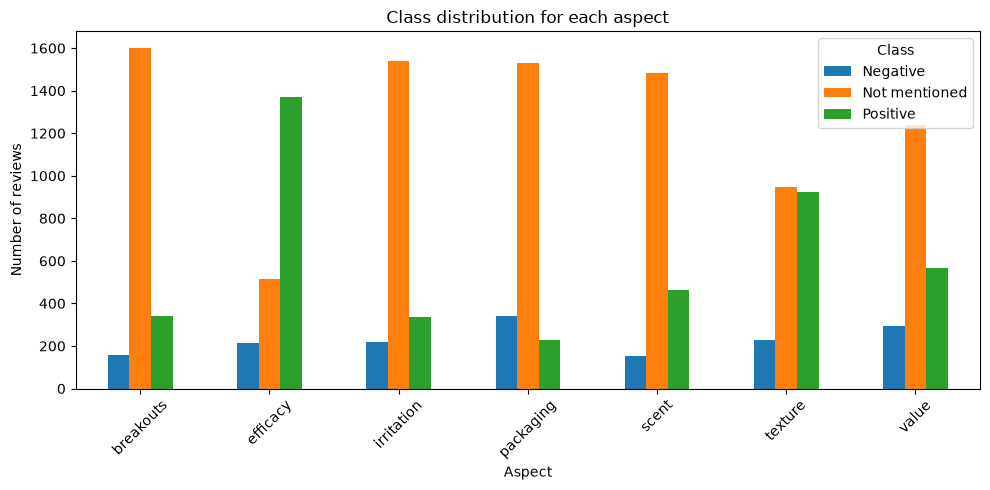

In [7]:
# Description: Assemble a DataFrame for plotting and display a bar chart of class counts
plot_data = []

for aspect in ASPECTS:
    counts = df[f"{aspect}_label"].value_counts().sort_index()

    for label in [0,1,2]:
        plot_data.append({
            "Aspect": aspect,
            "Class": label_names[label],
            "Count": counts.get(label,0)
        })

plot_df = pd.DataFrame(plot_data)

pivot = plot_df.pivot(index="Aspect", columns="Class", values="Count")

pivot.plot(kind="bar", figsize=(10,5))

plt.ylabel("Number of reviews")
plt.title("Class distribution for each aspect")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

### Step 5: Train / validation / test split (70/15/15)

In [8]:
# Description: Perform random splits, print sizes, and compare label distributions between train and test
train_df, temp_df = train_test_split(df, test_size=0.3, random_state=42)
val_df, test_df = train_test_split(temp_df, test_size=0.5, random_state=42)


print(f"Train: {len(train_df)} reviews")
print(f"Validation: {len(val_df)} reviews")
print(f"Test: {len(test_df)} reviews")

label_names = {0: "Not mentioned", 1: "Positive", 2: "Negative"}

for aspect in ASPECTS:
    train_dist = train_df[f"{aspect}_label"].value_counts(normalize=True).sort_index()
    test_dist = test_df[f"{aspect}_label"].value_counts(normalize=True).sort_index()

    comparison = pd.DataFrame({
        "Train": train_dist,
        "Test": test_dist
    }).fillna(0)

    comparison.index = [label_names[i] for i in comparison.index]

    print(f"\n=== {aspect.upper()} ===")
    print(comparison.round(3))

Train: 1469 reviews
Validation: 315 reviews
Test: 315 reviews

=== TEXTURE ===
               Train   Test
Not mentioned  0.442  0.502
Positive       0.445  0.410
Negative       0.114  0.089

=== SCENT ===
               Train   Test
Not mentioned  0.707  0.698
Positive       0.216  0.241
Negative       0.077  0.060

=== BREAKOUTS ===
               Train   Test
Not mentioned  0.762  0.778
Positive       0.167  0.140
Negative       0.071  0.083

=== IRRITATION ===
               Train   Test
Not mentioned  0.743  0.749
Positive       0.157  0.152
Negative       0.099  0.098

=== EFFICACY ===
               Train   Test
Not mentioned  0.237  0.270
Positive       0.660  0.648
Negative       0.103  0.083

=== PACKAGING ===
               Train   Test
Not mentioned  0.727  0.737
Positive       0.108  0.117
Negative       0.165  0.146

=== VALUE ===
               Train   Test
Not mentioned  0.594  0.590
Positive       0.261  0.286
Negative       0.145  0.124


Class distributions for all seven aspects remained similar between train and test
(differences generally within a few percentage points) — the random split didn't need
manual stratification.

### Step 6: Tokenization setup

In [ ]:
# Description: Select device, load tokenizer, and check token lengths for a sample of reviews to determine truncation needs
DEVICE = torch.device("mps" if torch.backends.mps.is_available() else "cpu")
print("Using device:", DEVICE)

MODEL_NAME = "distilbert-base-uncased"
tokenizer = DistilBertTokenizerFast.from_pretrained(MODEL_NAME)

# Use the full cleaned dataset (what Phase 4 actually runs on), not the 2,099 labeled subset
df_full = pd.read_csv("skincare_reviews_clean.csv", usecols=["review_text"])

n = min(20000, len(df_full))
sample_texts = df_full["review_text"].sample(n, random_state=42).astype(str).tolist()

lengths = np.array([len(x) for x in tokenizer(sample_texts, truncation=False)["input_ids"]])

print("Token length percentiles (50/90/95/99/100):", np.percentile(lengths, [50, 90, 95, 99, 100]))
print(f"Share truncated at 256: {(lengths > 256).mean():.2%}")
print(f"Share truncated at 384: {(lengths > 384).mean():.2%}")


Token indices sequence length is longer than the specified maximum sequence length for this model (553 > 512). Running this sequence through the model will result in indexing errors


Token length percentiles (50/90/95/99/100): [ 64.   145.   181.   290.02 646.  ]
Share truncated at 256: 1.64%
Share truncated at 384: 0.29%


In [ ]:
# Set MAX_LEN based on the data and define aspects

MAX_LEN = 256  # Measured on a 20k sample of the full dataset:
               # median 64, 95th pct 181, 99th pct 290 tokens; 1.64% of reviews exceed 256
               # and are truncated (0.29% exceed 384)

ASPECTS = ["texture", "scent", "breakouts", "irritation", "efficacy", "packaging", "value"]

Using device: mps


### Step 7: Dataset class — tokenizes text, returns all 7 aspect labels together

In [ ]:

# Dataset that tokenizes review text and returns tensors + labels for each aspect
class AspectReviewDataset(Dataset):

    def __init__(self, df, tokenizer, aspects, max_len=256):
        # Store review texts as a list
        self.texts = df["review_text"].tolist()

        # Store labels for each aspect
        self.labels = {
            aspect: df[f"{aspect}_label"].tolist()
            for aspect in aspects
        }

        # Save tokenizer and settings for later use
        self.tokenizer = tokenizer
        self.aspects = aspects
        self.max_len = max_len

    def __len__(self):
        # Return the total number of reviews
        return len(self.texts)

    def __getitem__(self, idx):
        # Tokenize one review and convert it into model inputs
        encoding = self.tokenizer(
            self.texts[idx],
            truncation=True,              # Cut text if it is longer than max_len
            padding="max_length",         # Pad shorter texts to max_len
            max_length=self.max_len,      # Maximum number of tokens
            return_tensors="pt"           # Return PyTorch tensors
        )

        # Create the input dictionary for the model
        item = {
            # Remove the extra batch dimension
            "input_ids": encoding["input_ids"].squeeze(0),

            # Shows which tokens are real text vs padding
            "attention_mask": encoding["attention_mask"].squeeze(0),
        }

        # Add the label for each aspect
        for aspect in self.aspects:
            item[f"{aspect}_label"] = torch.tensor(
                self.labels[aspect][idx],
                dtype=torch.long
            )

        # Return tokenized review + all aspect labels
        return item

### Step 8: Model — shared DistilBERT backbone, one linear head per aspect

In [ ]:
# Description: Multi-aspect classifier using DistilBERT
# with one classification head for each aspect
class MultiAspectClassifier(nn.Module):

    def __init__(self, model_name, aspects, num_classes=3, dropout=0.3):
        super().__init__()

        # Load pretrained DistilBERT
        self.bert = DistilBertModel.from_pretrained(model_name)

        # Save the list of aspects
        self.aspects = aspects

        # Get the size of DistilBERT's output representation
        # Usually 768 for distilbert-base-uncased
        hidden_size = self.bert.config.hidden_size

        # Dropout helps reduce overfitting during training
        self.dropout = nn.Dropout(dropout)

        # Create one classification head for each aspect
        # Each head predicts 3 classes:
        # 0 = Not mentioned, 1 = Positive, 2 = Negative
        self.heads = nn.ModuleDict({
            aspect: nn.Linear(hidden_size, num_classes)
            for aspect in aspects
        })

    def forward(self, input_ids, attention_mask):

        # Pass the tokenized review through DistilBERT
        outputs = self.bert(
            input_ids=input_ids,
            attention_mask=attention_mask
        )

        # Take the representation of the first token ([CLS] position)
        # This vector summarizes the whole review
        pooled = outputs.last_hidden_state[:, 0]

        # Apply dropout before classification
        pooled = self.dropout(pooled)

        # Use a separate classification head for each aspect
        logits = {
            aspect: self.heads[aspect](pooled)
            for aspect in self.aspects
        }

        # Return predictions for all aspects
        return logits

### Step 9: Build datasets/loaders and sanity-check the model's output shapes

In [48]:
# Description: Instantiate datasets and data loaders for train/val/test
set_seed()
train_dataset = AspectReviewDataset(train_df, tokenizer, ASPECTS, max_len=MAX_LEN)
val_dataset = AspectReviewDataset(val_df, tokenizer, ASPECTS, max_len=MAX_LEN)
test_dataset = AspectReviewDataset(test_df, tokenizer, ASPECTS, max_len=MAX_LEN)

BATCH_SIZE = 16
train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE)

print("Train batches:", len(train_loader))
print("Val batches:", len(val_loader))

Train batches: 92
Val batches: 20


In [49]:
# Description: Create model, run one batch through it as a quick sanity check of shapes
model = MultiAspectClassifier(MODEL_NAME, ASPECTS).to(DEVICE)

# Quick sanity check: run one batch through the model
batch = next(iter(train_loader))
input_ids = batch["input_ids"].to(DEVICE)
attention_mask = batch["attention_mask"].to(DEVICE)

with torch.no_grad():
    logits = model(input_ids, attention_mask)

for aspect, out in logits.items():
    print(aspect, out.shape)  # should be [batch_size, 3] for each aspect

texture torch.Size([16, 3])
scent torch.Size([16, 3])
breakouts torch.Size([16, 3])
irritation torch.Size([16, 3])
efficacy torch.Size([16, 3])
packaging torch.Size([16, 3])
value torch.Size([16, 3])


### Step 10: Training utilities — loss, optimizer, and evaluation function

In [50]:
# Description: Training utilities: optimizer, loss, compute_loss helper, and evaluation function
from torch.optim import AdamW
from sklearn.metrics import f1_score
import numpy as np

criterion = nn.CrossEntropyLoss()
optimizer = AdamW(model.parameters(), lr=2e-5)

EPOCHS = 100
best_val_f1 = 0
patience = 2
counter = 0

def compute_loss(logits, batch):
    """Sum cross-entropy loss across all 7 aspect heads."""
    total_loss = 0
    for aspect in ASPECTS:
        labels = batch[f"{aspect}_label"].to(DEVICE)
        total_loss += criterion(logits[aspect], labels)
    return total_loss

def evaluate(model, loader):
    model.eval()
    all_preds = {aspect: [] for aspect in ASPECTS}
    all_labels = {aspect: [] for aspect in ASPECTS}
    total_loss = 0

    with torch.no_grad():
        for batch in loader:
            input_ids = batch["input_ids"].to(DEVICE)
            attention_mask = batch["attention_mask"].to(DEVICE)
            logits = model(input_ids, attention_mask)

            total_loss += compute_loss(logits, batch).item()

            for aspect in ASPECTS:
                preds = torch.argmax(logits[aspect], dim=1).cpu().numpy()
                labels = batch[f"{aspect}_label"].numpy()

                all_preds[aspect].extend(preds)
                all_labels[aspect].extend(labels)

    avg_loss = total_loss / len(loader)

    macro_f1 = {
        aspect: f1_score(
            all_labels[aspect],
            all_preds[aspect],
            average="macro",
            zero_division=0
        )
        for aspect in ASPECTS
    }

    return avg_loss, macro_f1, all_preds, all_labels

### Step 11: Train, with early stopping and checkpointing

Saves the best checkpoint (by validation macro F1) to `aspect_sentiment_model_final.pt`, and
stops automatically if validation F1 doesn't improve for 2 consecutive epochs.

In [ ]:
# Description: Training loop with validation, early stopping, and checkpoint saving

# Repeat training for the specified number of epochs
for epoch in range(EPOCHS):

    # Put the model into training mode
    model.train()

    # Start counting the training loss for this epoch
    train_loss = 0

    # Go through the training data batch by batch
    for batch in train_loader:

        # Clear gradients from the previous batch
        optimizer.zero_grad()

        # Move input data to the selected device (MPS or CPU)
        input_ids = batch["input_ids"].to(DEVICE)
        attention_mask = batch["attention_mask"].to(DEVICE)

        # Run the batch through the model
        # Returns predictions for all 7 aspects
        logits = model(input_ids, attention_mask)

        # Calculate the total loss across all aspects
        loss = compute_loss(logits, batch)

        # Calculate gradients
        loss.backward()

        # Update the model's weights using the gradients
        optimizer.step()

        # Add this batch's loss to the epoch total
        train_loss += loss.item()

    # Calculate average training loss for the epoch
    train_loss /= len(train_loader)

    # Evaluate the model on validation data
    val_loss, val_f1, _, _ = evaluate(model, val_loader)

    # Calculate the average F1 score across all aspects
    val_macro_f1 = np.mean(list(val_f1.values()))

    # Print results for this epoch
    print(f"Epoch {epoch+1}/{EPOCHS}")
    print(f"Train Loss: {train_loss:.4f}")
    print(f"Val Loss: {val_loss:.4f}")
    print(f"Val Macro F1: {val_macro_f1:.4f}")

    # Check if validation F1 improved
    if val_macro_f1 > best_val_f1:

        # Save the new best F1 score
        best_val_f1 = val_macro_f1

        # Reset the early-stopping counter
        counter = 0

        # Save the best model
        torch.save({
            "model_state_dict": model.state_dict(),
            "tokenizer": MODEL_NAME,
            "aspects": ASPECTS
        }, "aspect_sentiment_model_final.pt")

        print("Best model saved.")

    else:
        # No improvement → increase the patience counter
        counter += 1

    # Stop training if the model hasn't improved for too many epochs
    if counter >= patience:
        print("Early stopping.")
        break

Epoch 1/100
Train Loss: 5.6678
Val Loss: 4.8129
Val Macro F1: 0.4061
Best model saved.
Epoch 2/100
Train Loss: 4.1685
Val Loss: 3.7632
Val Macro F1: 0.5999
Best model saved.
Epoch 3/100
Train Loss: 3.2523
Val Loss: 3.3145
Val Macro F1: 0.6482
Best model saved.
Epoch 4/100
Train Loss: 2.6053
Val Loss: 3.1501
Val Macro F1: 0.7065
Best model saved.
Epoch 5/100
Train Loss: 2.0638
Val Loss: 2.8832
Val Macro F1: 0.7421
Best model saved.
Epoch 6/100
Train Loss: 1.6790
Val Loss: 2.8704
Val Macro F1: 0.7416
Epoch 7/100
Train Loss: 1.3361
Val Loss: 2.8242
Val Macro F1: 0.7557
Best model saved.
Epoch 8/100
Train Loss: 1.0811
Val Loss: 2.9195
Val Macro F1: 0.7539
Epoch 9/100
Train Loss: 0.8947
Val Loss: 2.9240
Val Macro F1: 0.7587
Best model saved.
Epoch 10/100
Train Loss: 0.7123
Val Loss: 2.8916
Val Macro F1: 0.7637
Best model saved.
Epoch 11/100
Train Loss: 0.6086
Val Loss: 3.0309
Val Macro F1: 0.7424
Epoch 12/100
Train Loss: 0.5094
Val Loss: 2.9483
Val Macro F1: 0.7576
Early stopping.


### Step 12: Evaluate the best checkpoint on the held-out test set

Accuracy could look good just by predicting "Not mentioned" often
F1(recall, precision) helps evaluate each class, while macro F1 prevents the large class from hiding poor performance on the smaller classes . 
F1 score = combines precision and recall into one score. Useful when classes are imbalanced like in this case.
Precision: Of the things I predicted as Positive, how many were actually Positive?
Recall: Of the actual Positive examples, how many did I find?
Macro F1 = calculates F1 separately for each class and then gives every class equal weight.

In [ ]:
#Load the best checkpoint, evaluate on the test set, and print the final metrics

# Load the saved best model checkpoint
# map_location makes sure the model is loaded onto the selected device
checkpoint = torch.load(
    "aspect_sentiment_model_final.pt",
    map_location=DEVICE
)

# Restore the trained model weights from the checkpoint
model.load_state_dict(checkpoint["model_state_dict"])

# Put the model into evaluation mode
# This disables training-specific behavior such as Dropout
model.eval()

# Run the model on the test dataset
# Returns test loss, F1 scores, predictions, and true labels
test_loss, test_f1, test_preds, test_labels = evaluate(
    model,
    test_loader
)

# Print the overall test loss
print(f"Test Loss: {test_loss:.4f}")

# Print the F1 score for each aspect
for aspect, score in test_f1.items():
    print(f"{aspect:12} {score:.3f}")

Test Loss: 2.4870
texture      0.739
scent        0.877
breakouts    0.843
irritation   0.829
efficacy     0.712
packaging    0.835
value        0.757


### Step 13: Per-aspect Macro F1 chart

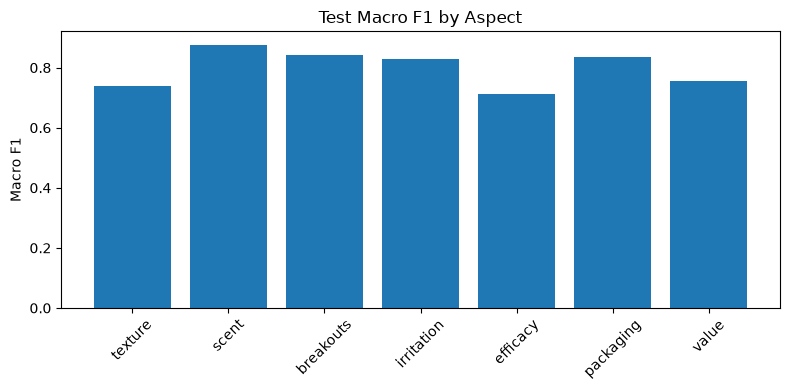

In [53]:
# Description: Plot a bar chart of test Macro F1 by aspect
import matplotlib.pyplot as plt

plt.figure(figsize=(8,4))

plt.bar(test_f1.keys(), test_f1.values())

plt.ylabel("Macro F1")
plt.title("Test Macro F1 by Aspect")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

### Step 14: Full classification report per aspect (precision/recall/F1 by class)

|        F1 | Rough interpretation |
| --------: | -------------------- |
|    < 0.50 | Poor                 |
| 0.50–0.70 | Moderate             |
| 0.70–0.80 | Good                 |
| 0.80–0.90 | Very good            |
|    > 0.90 | Excellent            |


In [54]:

for aspect in ASPECTS:
    print(f"\n{'='*20} {aspect.upper()} {'='*20}")

    print(classification_report(
        test_labels[aspect],
        test_preds[aspect],
        target_names=["Not mentioned","Positive","Negative"],
        zero_division=0
    ))


==================== TEXTURE ====================
               precision    recall  f1-score   support

Not mentioned       0.82      0.82      0.82       158
     Positive       0.80      0.83      0.82       129
     Negative       0.62      0.54      0.58        28

     accuracy                           0.80       315
    macro avg       0.75      0.73      0.74       315
 weighted avg       0.80      0.80      0.80       315


==================== SCENT ====================
               precision    recall  f1-score   support

Not mentioned       0.98      0.99      0.98       220
     Positive       0.96      0.86      0.90        76
     Negative       0.67      0.84      0.74        19

     accuracy                           0.95       315
    macro avg       0.87      0.90      0.88       315
 weighted avg       0.95      0.95      0.95       315


==================== BREAKOUTS ====================
               precision    recall  f1-score   support

Not mentioned  

### Step 15: Summary table, sorted by Macro F1

In [55]:
# Summary table of Macro F1 scores per aspect

summary = pd.DataFrame({
    "Aspect": list(test_f1.keys()),
    "Macro F1": list(test_f1.values())
})

summary = summary.sort_values("Macro F1", ascending=False)

summary

,Aspect,Macro F1
1,scent,0.877054
2,breakouts,0.842562
5,packaging,0.835357
3,irritation,0.829452
6,value,0.756862
0,texture,0.738834
4,efficacy,0.711592


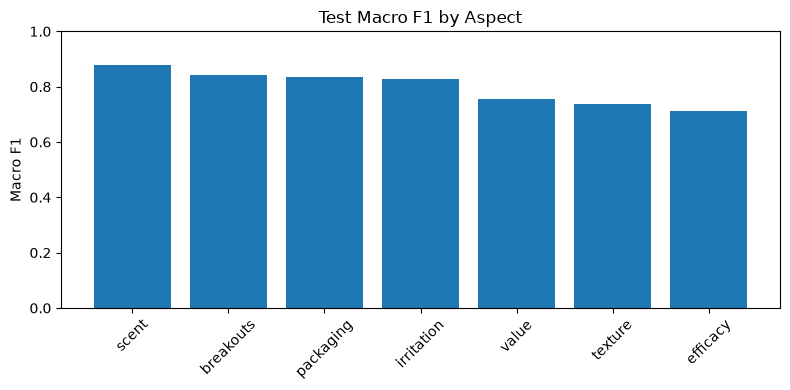

In [56]:
# Description: Plot the sorted Macro F1 summary by aspect
plt.figure(figsize=(8,4))
plt.bar(summary["Aspect"], summary["Macro F1"])
plt.ylim(0,1)
plt.ylabel("Macro F1")
plt.title("Test Macro F1 by Aspect")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

## Results and iteration history

The model was retrained as Phase 2's labeled dataset grew. The earlier two columns below are
from those intermediate runs, which are not re-run in this notebook (see Phase 2, Steps 10–11,
for how each supplementary batch was produced). The final column is the run in this notebook
(n=2,099 labeled reviews, test n=315).

| Aspect | Original (n=1,499) | + targeted irritation (n=1,799) | + targeted packaging (n=2,099, final) |
|---|---|---|---|
| texture | 0.70 | 0.75 | **0.74** |
| scent | 0.74 | 0.89 | **0.88** |
| breakouts | 0.72 | 0.83 | **0.84** |
| irritation | 0.55 | 0.82 | **0.83** |
| efficacy | 0.60 | 0.66 | **0.71** |
| packaging | 0.62 | 0.57 | **0.84** |
| value | 0.69 | 0.68 | **0.76** |

*Test macro F1 per aspect. Rare-class test supports are small (19–48 examples), and results
come from a single seed, so differences of ±0.05 should not be over-interpreted.*

**Irritation's negative class** (the aspect that motivated the first supplementary round) went
from precision 0.17 / recall 0.08 / F1 0.11 in the first run to precision 0.79 / recall 0.71 /
F1 0.75 in the final model. Targeted labeling directly fixed the problem it was designed to fix.

**Packaging's negative class** also improved after its targeted batch: precision 0.84 /
recall 0.89 / F1 0.86 in the final model, now one of the strongest classes.

**Weakest classes in the final model** (test F1): texture-negative 0.58, efficacy-negative
0.64, value-negative 0.65, and efficacy-not-mentioned 0.63. Efficacy and texture have the
lowest macro F1 overall (0.71 and 0.74).

**Limitations:**
- All training labels are LLM-generated (Llama 3.1 8B) and have not been validated against
  human labels, so this model learns to approximate the LLM's judgments, not independent
  ground truth. Reported F1 scores measure agreement with the LLM labels, not correctness.
  Validating on a small randomly sampled, human-labeled set (~100-150 reviews) would be the main
  next step and has not been done.
- The two supplementary batches were deliberately class-imbalanced toward the rare classes
  they targeted (e.g. 257 of 300 packaging-batch reviews are negative), so the *overall*
  training and test sets no longer reflect the real-world aspect distribution. This was
  intentional for class balance, but it means test scores are not representative of
  performance on a random review, and predicted negative rates on the full dataset
  (especially packaging) may be inflated.
- Rare-class test supports are small (19-48 examples) and results come from a single seed,
  so small F1 differences should not be over-interpreted.